# Vedio compression  - GOP = IPPP
# E19312

# Libraries

In [331]:
import cv2
import matplotlib.pyplot as plt
import numpy as np
import json

# Functions

In [332]:
def DevideToMacroblocks(image,macroblocksize):
    macroblocks = []
    for i in range(0,image.shape[0],macroblocksize):
        for j in range(0,image.shape[1],macroblocksize):
            macroblock = image[i:i+macroblocksize,j:j+macroblocksize]
            macroblocks.append(macroblock)
    return macroblocks

In [333]:
def dct(macroblocks):
    dctblocks =[]
    for i in macroblocks:
        dct_block= cv2.dct(np.float32(i))
        dctblocks.append(dct_block)
    return dctblocks

In [334]:
def Quantize(dctblocks, Q_factor):
    Q_matrix = np.array([
        [16, 11, 10, 16, 24, 40, 51, 61],
        [12, 12, 14, 19, 26, 58, 60, 55],
        [14, 13, 16, 24, 40, 57, 69, 56],
        [14, 17, 22, 29, 51, 87, 80, 62],
        [18, 22, 37, 56, 68, 109, 103, 77],
        [24, 35, 55, 64, 81, 104, 113, 92],
        [49, 64, 78, 87, 103, 121, 120, 101],
        [72, 92, 95, 98, 112, 100, 103, 99]])
    quantized_dctblocks = []
    scale_matrix = Q_matrix*Q_factor
    for i in dctblocks:
        quantized_block = np.round(i/ scale_matrix).astype(int)  # Element-wise division
        quantized_dctblocks.append(quantized_block)

    return quantized_dctblocks

In [335]:
def dc_extract(quantized_dctblocks):
    dc_coefficients = []
    for i in quantized_dctblocks:
        dc_coefficients.append(i[0,0])

    return dc_coefficients

In [336]:
def zigzag_scan(block):
    rows, cols = block.shape
    solution = [[] for i in range(rows + cols - 1)]
    
    for i in range(rows):
        for j in range(cols):
            sum = i + j
            if(sum % 2 == 0):
                solution[sum].insert(0, block[i][j])
            else:
                solution[sum].append(block[i][j])
    
    return [j for sub in solution for j in sub]

def ac_extract(quantized_dctblocks):
    ac_coefficients = []
    for block in quantized_dctblocks:
        zigzag = zigzag_scan(block)
        ac_coefficients.append(zigzag[1:])  # Exclude the DC coefficient
    return ac_coefficients 

In [337]:
def dpcm(dc_coefficients):
    dc_values = np.array(dc_coefficients)
    dpcm_encoded=np.zeros_like(dc_values)
    dpcm_encoded[0]= dc_values[0]
    dpcm_encoded[1:] = np.diff(dc_values)

    return dpcm_encoded

In [338]:
def runlength(ac_coefficients):
    ac_coeffi = np.array(ac_coefficients).flatten()
    current_val = ac_coeffi[0]
    runlength_encoded=[]
    count = 0
    for i in ac_coeffi:
        if i == current_val:
            count+=1
        else:
            runlength_encoded.append(current_val)
            runlength_encoded.append(count)
            current_val = i
            count = 1

    runlength_encoded.append(current_val)
    runlength_encoded.append(count)

    return runlength_encoded

In [339]:
from collections import Counter
import heapq

class HuffmanNode:
    def __init__(self, symbol, freq):
        self.symbol = symbol
        self.freq = freq
        self.left = None
        self.right = None

    def __lt__(self, other):
        return self.freq < other.freq

def build_huffman_tree(frequencies):
    heap = [HuffmanNode(symbol, freq) for symbol, freq in frequencies.items()]
    heapq.heapify(heap)

    while len(heap) > 1:
        node1 = heapq.heappop(heap)
        node2 = heapq.heappop(heap)
        merged = HuffmanNode(None, node1.freq + node2.freq)
        merged.left = node1
        merged.right = node2
        heapq.heappush(heap, merged)

    return heap[0]

def generate_huffman_codes(node, prefix="", codebook=None):
    if codebook is None:
        codebook = {}

    if node.symbol is not None:
        codebook[node.symbol] = prefix
    else:
        generate_huffman_codes(node.left, prefix + "0", codebook)
        generate_huffman_codes(node.right, prefix + "1", codebook)

    return codebook

def huffman_encode(data, codebook):
    return ''.join(codebook[symbol] for symbol in data)


def huffman_decode(encoded_data, huffman_dict):
    reverse_dict = {v: k for k, v in huffman_dict.items()}  # Reverse mapping
    decoded_data, buffer = [], ""
    for bit in encoded_data:
        buffer += bit
        if buffer in reverse_dict:
            decoded_data.append(int(reverse_dict[buffer]))  # Convert to int
            buffer = ""

    return np.array(decoded_data)

In [340]:
def inverse_runlength(ac_huffman_decoded_data):
    rl_decoded_data = []
    for i in range(0, len(ac_huffman_decoded_data), 2):
        value = ac_huffman_decoded_data[i]
        count = ac_huffman_decoded_data[i + 1]
        rl_decoded_data.extend([value] * count)
    rl_decoded_data = np.array_split(rl_decoded_data, np.ceil(len(rl_decoded_data) / 63))
    
    return rl_decoded_data

In [341]:
def inverse_dpcm(dc_huffman_decoded_data):
    dc_values = np.array(dc_huffman_decoded_data)
    dpcm_decoded=np.zeros_like(dc_values)
    dpcm_decoded[0]= dc_values[0]
    for i in range(1,len(dc_values)):
        dpcm_decoded[i] = dc_values[i]+dpcm_decoded[i-1]

    return dpcm_decoded

In [342]:
def inverse_zigzag_scan(zigzag_array, rows=8, cols=8):
    solution = np.zeros((rows, cols), dtype=int)
    index = -1
    bound = rows + cols - 1
    for i in range(bound):
        if i % 2 == 0:
            for j in range(i, -1, -1):
                if j < rows and (i - j) < cols:
                    index += 1
                    solution[j][i - j] = zigzag_array[index]
        else:
            for j in range(i + 1):
                if j < rows and (i - j) < cols:
                    index += 1
                    solution[j][i - j] = zigzag_array[index]
    return solution

In [343]:
def deQuantize(inverse_zigzag_blocks, Q_factor):
    Q_matrix = np.array([
        [16, 11, 10, 16, 24, 40, 51, 61],
        [12, 12, 14, 19, 26, 58, 60, 55],
        [14, 13, 16, 24, 40, 57, 69, 56],
        [14, 17, 22, 29, 51, 87, 80, 62],
        [18, 22, 37, 56, 68, 109, 103, 77],
        [24, 35, 55, 64, 81, 104, 113, 92],
        [49, 64, 78, 87, 103, 121, 120, 101],
        [72, 92, 95, 98, 112, 100, 103, 99]])
    dequantized_blocks = []
    scale_matrix = Q_matrix * Q_factor
    for block in inverse_zigzag_blocks:
        dequantized_block = block * scale_matrix
        dequantized_blocks.append(dequantized_block)

    return dequantized_blocks

In [344]:
def inverse_dct(dequantized_blocks):
    inverse_dct_blocks = []
    for block in dequantized_blocks:
        inverse_dct_block = cv2.idct(np.float32(block))
        inverse_dct_blocks.append(inverse_dct_block)

    return inverse_dct_blocks

In [345]:
def reconstruct_image(inverse_dct_blocks, image_shape, macroblocksize):
    h, w = image_shape
    reconstructed_image = np.zeros((h, w), dtype=np.float32)

    idx = 0
    for i in range(0, h, macroblocksize):
        for j in range(0, w, macroblocksize):
            reconstructed_image[i:i+macroblocksize, j:j+macroblocksize] = inverse_dct_blocks[idx]
            idx += 1
    # print("Reconstructed Image Shape:", reconstructed_image.shape)

    return reconstructed_image

In [346]:
def padding(image, macroblocksize):
    h, w = image.shape
    h_pad = (macroblocksize - h % macroblocksize) % macroblocksize
    w_pad = (macroblocksize - w % macroblocksize) % macroblocksize
    padded_image = np.pad(image, ((0, h_pad), (0, w_pad)), mode='constant', constant_values=0)

    return padded_image

In [347]:
def inverse_padding(image,macroblocksize):
    h, w = image.shape
    h_pad = (macroblocksize - h % macroblocksize) % macroblocksize
    w_pad = (macroblocksize - w % macroblocksize) % macroblocksize

    # # Handle cases where no padding was added
    # if h_pad == 0:
    #     h_pad = None  # Ensures slicing does not remove valid data
    # if w_pad == 0:
    #     w_pad = None  # Same for width
        
    return image[:h-h_pad, :w-w_pad]

In [348]:
def calculate_psnr(original, reconstructed):
    mse = np.mean((original - reconstructed) ** 2)
    if mse == 0:
        return float('inf')
    max_pixel = 255.0
    psnr = 20 * np.log10(max_pixel / np.sqrt(mse))
    return psnr

In [349]:
def motion_estimate(macroblocks, ref_macroblocks, image_shape, macroblock_size=8, P=7):
    h_macroblocks = image_shape[0] // macroblock_size  #height
    w_macroblocks= image_shape[1]  // macroblock_size #width

    macroblocks = np.array(macroblocks, dtype=object).reshape(h_macroblocks, w_macroblocks, macroblock_size, macroblock_size)
    # print(macroblocks.shape)
    ref = reconstruct_image(ref_macroblocks, image_shape, macroblock_size)

    Mv = []  # Motion vectors
    Res = []  # Residual blocks

    for i in range(h_macroblocks):
        for j in range(w_macroblocks):
            # Get the macroblock from the current frame
            c_Block = macroblocks[i][j].astype(np.int16)
            
            # Initialize SAD and motion vector
            SAD = 0
            count=1
            c_Mv = [0, 0]  # Default motion vector
            c_Res = np.zeros_like(c_Block)  # Default residual block

            # starting indexes of the macroblock
            xB= i*macroblock_size
            yB= j*macroblock_size

            for k in range(-P, P + 1):
                for l in range(-P, P + 1):
                    xS =xB+k
                    yS =yB+l
                    xL = xS+ macroblock_size - 1  # 7 = macroblock_size - 1
                    yL = yS+ macroblock_size - 1

                    # Ensure search is within bounds
                    if xS >= 0 and yS >= 0 and xS + macroblock_size <= image_shape[0] and yS + macroblock_size <= image_shape[1]:
                        ref_Block = ref[xS:xS+macroblock_size, yS:yS+macroblock_size].astype(np.int16)
                        # print(xS, xL, yS, yL)
                        # print(ref_Block.shape)
                        residual = np.sum(np.abs(c_Block - ref_Block))

                        if(count==1):
                            SAD = residual
                            c_Mv = [k,l]
                            c_Res = c_Block - ref_Block
                            count=count+1

                        elif residual < SAD:
                            SAD = residual
                            c_Mv = [k, l]
                            c_Res = c_Block - ref_Block

            # Store motion vector and residual block
            Mv.append(c_Mv)
            Res.append(np.array(c_Res))

    return Mv, Res

In [350]:
def inverse_motion_estimate(ref_macroblocks, Mv, Res, image_shape, macroblock_size=8):
    h_macroblocks = image_shape[0] // macroblock_size
    w_macroblocks = image_shape[1] // macroblock_size

    ref_image = reconstruct_image(ref_macroblocks, image_shape, macroblock_size)

    reconstructed_macroblocks = []
    index = 0
    for i in range(h_macroblocks):
        for j in range(w_macroblocks):
            motiion_vector = Mv[index]
            residual = Res[index]
            dx, dy = motiion_vector[0], motiion_vector[1]

            # Starting point of reference frame
            xB = i * macroblock_size
            yB = j * macroblock_size
            xS = xB + dx
            yS = yB + dy
            xL = xS + macroblock_size
            yL = yS + macroblock_size
            if xS >= 0 and yS >= 0 and xS + macroblock_size <= image_shape[0] and yS + macroblock_size <= image_shape[1]:
                ref_block = ref_image[xS:xL,yS:yL]
                reconstructed_block = ref_block + residual
                reconstructed_block = np.array(reconstructed_block).astype(np.uint8)
                reconstructed_macroblocks.append(reconstructed_block)
            index += 1

    return reconstructed_macroblocks

In [351]:
def encode_image(macroblocks, Q_factor): #macroblocksize
    # padded_frame = padding(frame, macroblocksize)
    # macroblocks = DevideToMacroblocks(padded_frame, macroblocksize)
    dct_blocks = dct(macroblocks)
    quantized_dct_blocks = Quantize(dct_blocks, Q_factor)
    dc_coefficients = dc_extract(quantized_dct_blocks)
    ac_coefficients = ac_extract(quantized_dct_blocks)
    dpcm_encoded = dpcm(dc_coefficients)
    runlength_encoded = runlength(ac_coefficients)

    # Huffman Encoding
    dc_frequencies = Counter(dpcm_encoded)
    dc_huffman_tree = build_huffman_tree(dc_frequencies)
    dc_huffman_dict = generate_huffman_codes(dc_huffman_tree)
    dc_huffman_encoded = huffman_encode(dpcm_encoded, dc_huffman_dict)

    ac_frequencies = Counter(runlength_encoded)
    ac_huffman_tree = build_huffman_tree(ac_frequencies)
    ac_huffman_dict = generate_huffman_codes(ac_huffman_tree)
    ac_huffman_encoded = huffman_encode(runlength_encoded, ac_huffman_dict)

    return dc_huffman_encoded, ac_huffman_encoded, dc_huffman_dict, ac_huffman_dict

In [352]:
def decode_image(dc_huffman_encoded, ac_huffman_encoded, dc_huffman_dict, ac_huffman_dict, Q_factor): #image_shape , macroblocksize,
    # Huffman Decoding
    dpcm_encoded = huffman_decode(dc_huffman_encoded, dc_huffman_dict)
    runlength_encoded = huffman_decode(ac_huffman_encoded, ac_huffman_dict) 
    ac_coefficients = inverse_runlength(runlength_encoded)
    dc_coefficients = inverse_dpcm(dpcm_encoded)

    inverse_zigzag_blocks = []
    for i in range(len(ac_coefficients)):
        zigzag_array = np.insert(ac_coefficients[i], 0, dc_coefficients[i])
        inverse_zigzag_block = inverse_zigzag_scan(zigzag_array)
        inverse_zigzag_blocks.append(inverse_zigzag_block)

    dequantized_blocks = deQuantize(inverse_zigzag_blocks, Q_factor)
    inverse_dct_blocks = inverse_dct(dequantized_blocks)
    # reconstructed_image = reconstruct_image(inverse_dct_blocks, image_shape, macroblocksize)
    
    return inverse_dct_blocks

In [353]:
def MV_huffman_encode(MV):
    MV = np.array(MV)
    MV_encoded = MV.flatten()
    MV_frequencies = Counter(MV_encoded)
    MV_huffman_tree = build_huffman_tree(MV_frequencies)
    MV_huffman_dict = generate_huffman_codes(MV_huffman_tree)
    MV_huffman_encoded = huffman_encode(MV_encoded, MV_huffman_dict)

    return MV_huffman_encoded, MV_huffman_dict

In [354]:
def MV_huffman_decode(MV_huffman_encoded, MV_huffman_dict):
    MV_encoded = huffman_decode(MV_huffman_encoded, MV_huffman_dict)
    MV = MV_encoded.reshape(-1, 2)
    return MV

# Frame extraction 

In [355]:
video_path = "video1(1080p).mp4"  # Replace with your video path
video = cv2.VideoCapture(video_path)
total_frames = int(video.get(cv2.CAP_PROP_FRAME_COUNT))
print("Total Frames: ", total_frames)

num_frames = 10
frames =[]
for frame_num in range(1, num_frames + 1):
    ret, frame = video.read()
    if not ret:
        break
    frame_filename = f"frames/frame{frame_num}.jpg"
    cv2.imwrite(frame_filename, frame)
    frames.append(frame_filename)

video.release()

Total Frames:  200


In [356]:
def get_video_fps(video_path):
    cap = cv2.VideoCapture(video_path)
    
    if not cap.isOpened():
        print("Error: Could not open video.")
        return None
    
    fps = cap.get(cv2.CAP_PROP_FPS)
    cap.release()
    
    return fps

# Example usage
video_path = "video1(1080p).mp4"  # Replace with your video file path
fps = get_video_fps(video_path)

if fps:
    print(f"Frame Rate (FPS): {fps}")

Frame Rate (FPS): 30.0


# 3.2

In [400]:
macroblocksize = 8
Q_factor = 20.5

# Create a directory to store the decoded frames
import os
if not os.path.exists(f"decoded_frames/decoded_frames_{Q_factor}"):
    os.makedirs(f"decoded_frames/decoded_frames_{Q_factor}")

for i in range(1,len(frames)+1):
    frame = frames[i-1]
    frame = cv2.imread(frame, cv2.IMREAD_GRAYSCALE)
    padded_frame = padding(frame, macroblocksize)
    macroblocks = DevideToMacroblocks(padded_frame, macroblocksize)
    
    #Assume IPPP GOP structure 
    # Encoding
    if i % 4 == 1:
        # ref_macroblocks = macroblocks
        dc_huffman_encoded, ac_huffman_encoded,dc_huffman_dict, ac_huffman_dict = encode_image(macroblocks, Q_factor)
        dc_huffman_dict = {int(k): v for k, v in dc_huffman_dict.items()}
        ac_huffman_dict = {int(k): v for k, v in ac_huffman_dict.items()}
        filename = f"decoded_frames/decoded_frames_{Q_factor}/frame_{i}_huffman_encoded_dc_datastream.txt"
        with open(filename, "w") as file:
            json.dump({"encoded_text": dc_huffman_encoded, "huffman_dict": dc_huffman_dict}, file)
        filename = f"decoded_frames/decoded_frames_{Q_factor}/frame_{i}_huffman_encoded_ac_datastream.txt"
        with open(filename, "w") as file:
            json.dump({"encoded_text": ac_huffman_encoded, "huffman_dict": ac_huffman_dict},file)

    else :
        motion_vectors, residuals = motion_estimate(macroblocks, ref_macroblocks, frame.shape, macroblocksize, P=7)
        dc_huffman_encoded, ac_huffman_encoded, dc_huffman_dict, ac_huffman_dict = encode_image(residuals, Q_factor)
        MV_huffman_encoded, MV_huffman_dict = MV_huffman_encode(motion_vectors)
        dc_huffman_dict = {int(k): v for k, v in dc_huffman_dict.items()}
        ac_huffman_dict = {int(k): v for k, v in ac_huffman_dict.items()}
        MV_huffman_dict = {int(k): v for k, v in MV_huffman_dict.items()}
        filename = f"decoded_frames/decoded_frames_{Q_factor}/frame_{i}_huffman_encoded_dc_datastream.txt"
        with open(filename, "w") as file:
            json.dump({"encoded_text": dc_huffman_encoded, "huffman_dict": dc_huffman_dict}, file)
        filename = f"decoded_frames/decoded_frames_{Q_factor}/frame_{i}_huffman_encoded_ac_datastream.txt"
        with open(filename, "w") as file:
            json.dump({"encoded_text": ac_huffman_encoded, "huffman_dict": ac_huffman_dict},file)
        filename = f"decoded_frames/decoded_frames_{Q_factor}/frame_{i}_huffman_encoded_MV_datastream.txt"
        with open(filename, "w") as file:
            json.dump({"encoded_text": MV_huffman_encoded, "huffman_dict": MV_huffman_dict},file)

    # Decoding
    decoded_macroblocks = decode_image(dc_huffman_encoded, ac_huffman_encoded, dc_huffman_dict, ac_huffman_dict, Q_factor)
    if i % 4 == 1:
        ref_macroblocks = decoded_macroblocks
        decoded_frame = decoded_macroblocks
        decoded_frame = reconstruct_image(decoded_frame, frame.shape, macroblocksize)
        decoded_frame = inverse_padding(decoded_frame,macroblocksize)
    else:
        decoded_residuals = decoded_macroblocks
        decoded_MV = MV_huffman_decode(MV_huffman_encoded, MV_huffman_dict)
        decoded_macroblocks = inverse_motion_estimate(ref_macroblocks, decoded_MV, decoded_residuals, frame.shape, macroblocksize)
        ref_macroblocks = decoded_residuals
        decoded_frame = reconstruct_image(decoded_macroblocks, frame.shape, macroblocksize)
        decoded_frame = inverse_padding(decoded_frame,macroblocksize)

    # plt.figure(figsize=(10, 10))
    # plt.subplot(1, 2, 1)
    # plt.imshow(frame, cmap='gray')
    # plt.title("Original Frame")
    
    # plt.subplot(1, 2, 2)
    # plt.imshow(decoded_frame, cmap='gray')
    # plt.title("Decoded Frame")
    # plt.show()

    cv2.imwrite(f"decoded_frames/decoded_frames_{Q_factor}/decoded_frame{i}.jpg", decoded_frame)

## Ploting residual image between frame 4 and frame 5

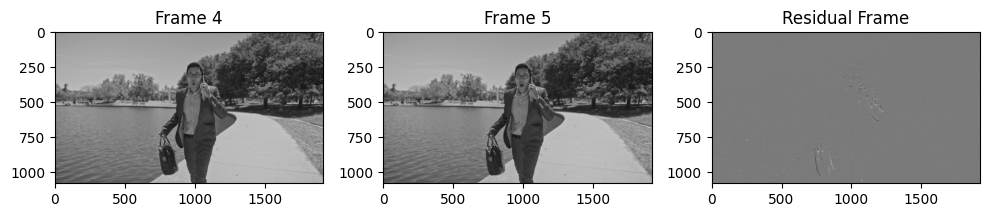

In [ ]:
frame_1_path = "frames/frame4.jpg"
frame_2_path = "frames/frame5.jpg"

frame_1 = cv2.imread(frame_1_path, cv2.IMREAD_GRAYSCALE)
frame_2 = cv2.imread(frame_2_path, cv2.IMREAD_GRAYSCALE)

# Convert grayscale to RGB for plotting
frame_1_rgb = cv2.cvtColor(frame_1, cv2.COLOR_GRAY2BGR)
frame_2_rgb = cv2.cvtColor(frame_2, cv2.COLOR_GRAY2BGR)

macroblocksize = 8
Q_factor = 10

padded_frame_1 = padding(frame_1, macroblocksize)
padded_frame_2 = padding(frame_2, macroblocksize)

macroblocks_1 = DevideToMacroblocks(padded_frame_1, macroblocksize)
macroblocks_2 = DevideToMacroblocks(padded_frame_2, macroblocksize)

MV, residual = motion_estimate(macroblocks_2, macroblocks_1, frame_1.shape, macroblocksize, P=7)

# Normalize residuals for display
residual_frame = reconstruct_image(residual, frame_1.shape, macroblocksize)
residual_display = ((residual_frame - residual_frame.min()) / 
                    (residual_frame.max() - residual_frame.min()) * 255).astype(np.uint8)

# Plot images
plt.figure(figsize=(10, 10))

plt.subplot(1, 3, 1)
plt.imshow(frame_1_rgb)  # Corrected variable
plt.title("Frame 4")

plt.subplot(1, 3, 2)
plt.imshow(frame_2_rgb)  # Corrected variable
plt.title("Frame 5")

plt.subplot(1, 3, 3)
plt.imshow(residual_display, cmap="gray")  # Ensure correct grayscale display
plt.title("Residual Frame")

plt.tight_layout()
plt.show()

## Ploting decoded frames for Q = 1

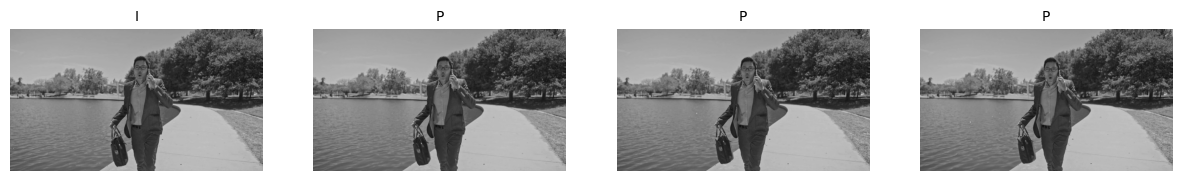

In [398]:
fig, axs = plt.subplots(1, 4, figsize=(15, 15))
for i in range(1, 5):
    # Set titles for each column (I-frame for the first, P-frames for others)
    axs[i-1].set_title('I' if i == 1 else 'P', fontsize=10)

    # Load and display original frame
    decoded_frame_q1 = cv2.imread(f"decoded_frames/decoded_frames_1/decoded_frame{i}.jpg")
    axs[i-1].imshow(decoded_frame_q1, cmap='gray')
    axs[i-1].axis('off')

# fig.text(0.5, 0.57, "Decoded Frames(Q=10)", ha='center', va='center', fontsize=10, fontweight='bold')
plt.show()


## Ploting decoded frames for Q = 10

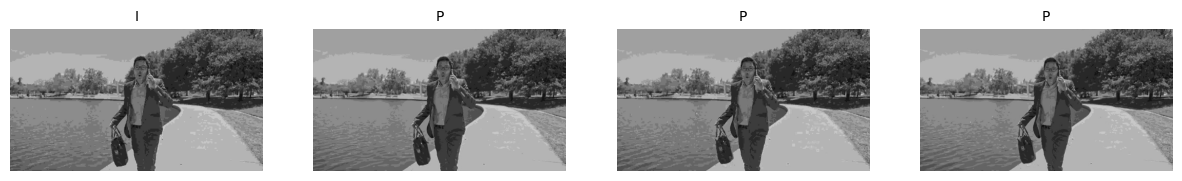

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(15, 15))
for i in range(1, 5):
    # Set titles for each column (I-frame for the first, P-frames for others)
    axs[i-1].set_title('I' if i == 1 else 'P', fontsize=10)

    # Load and display original frame
    decoded_frame_q10 = cv2.imread(f"decoded_frames/decoded_frames_10/decoded_frame{i}.jpg")
    axs[i-1].imshow(decoded_frame_q10, cmap='gray')
    axs[i-1].axis('off')

# fig.text(0.5, 0.57, "Decoded Frames(Q=10)", ha='center', va='center', fontsize=10, fontweight='bold')
plt.show()

## Ploting decoded frames for Q = 20.5

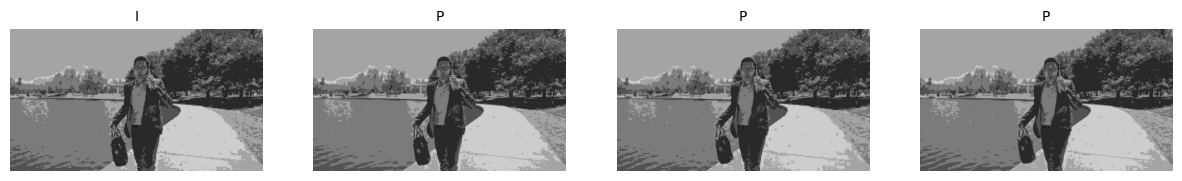

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(15, 15))
for i in range(1, 5):
    # Set titles for each column (I-frame for the first, P-frames for others)
    axs[i-1].set_title('I' if i == 1 else 'P', fontsize=10)

    # Load and display original frame
    decoded_frame_q = cv2.imread(f"decoded_frames/decoded_frames_20.5/decoded_frame{i}.jpg")
    axs[i-1].imshow(decoded_frame_q, cmap='gray')
    axs[i-1].axis('off')

# fig.text(0.5, 0.57, "Decoded Frames(Q=20.5)", ha='center', va='center', fontsize=10, fontweight='bold')
plt.show()

# 3.3 Improved hybrid video codec 

## 3.3.1

In [ ]:
def rate_optimize(input_image, R_Rate):    
    R = []
    D = []
    Qlevels_list = []
    
    macroblocksize = 8
    padded_image = padding(input_image, macroblocksize)
    macroblocks_image = DevideToMacroblocks(padded_image, macroblocksize)
   
    testQ = [1, 2, 4,7, 10, 20, 25, 40]
    # testQ = [40,50,60,70,80,90,100]
    
    j = 1
    k = 2  # Start from the second value of temp
    r = float('inf')
    expFlag = False
    ftFlag = False
    
    while True:
        if r > R_Rate:
            if j <= len(testQ) and not ftFlag:  # Initial Q value assignment
                Qlevel = testQ[j - 1]
                j += 1
            elif ftFlag or k == 10:
                Qlevel = temp[k - 2]
                break
            elif not ftFlag:
                expFlag = True
                print("Extrapolating Q")
                Qlevel += 5
        else:
            if j == 2:
                break
            elif not expFlag and k < 10:
                ftFlag = True
                temp = np.linspace(testQ[j - 2], testQ[j - 3], 10)
                Qlevel = temp[k - 1]
                k += 1
            elif expFlag:
                break
            elif k == 10:
                break
        
        
        # Encoding and decoding
        dc_huffman_encoded, ac_huffman_encoded, dc_huffman_dict, ac_huffman_dict = encode_image(macroblocks_image, Qlevel)
        Decoded_image = decode_image(dc_huffman_encoded, ac_huffman_encoded, dc_huffman_dict, ac_huffman_dict,Qlevel)
        Reconstruct_image= reconstruct_image(Decoded_image,input_image.shape, macroblocksize)
        IMG1 = inverse_padding(Reconstruct_image,macroblocksize)

        # Compute rate and distortion
        r = ((len(dc_huffman_encoded)+len(ac_huffman_encoded))*30) / 1000  # Rate in kBits per frame
        print(f"Qlevel = {Qlevel} , " , f"Bitrate = {r}")
        R.append(r)
        D.append(calculate_psnr(IMG1, input_image))
        Qlevels_list.append(Qlevel)
    
    print(f"Final Qlevel = {Qlevel}")
    
    return Qlevel , R, D ,Qlevels_list


In [ ]:
frame_1_path = "frames/frame1.jpg"
frame_1 = cv2.imread(frame_1_path, cv2.IMREAD_GRAYSCALE)
Qfactor,R,D,Qlevels_list= rate_optimize(frame_1,1500)
# print(Qfactor)

Qlevel = 1 ,  Bitrate = 30335.07
Qlevel = 2 ,  Bitrate = 18740.25
Qlevel = 4 ,  Bitrate = 10965.24
Qlevel = 7 ,  Bitrate = 6593.97
Qlevel = 10 ,  Bitrate = 4524.09
Qlevel = 20 ,  Bitrate = 2100.87
Qlevel = 25 ,  Bitrate = 1705.77
Qlevel = 40 ,  Bitrate = 1245.18
Qlevel = 38.333333333333336 ,  Bitrate = 1270.08
Qlevel = 36.666666666666664 ,  Bitrate = 1309.74
Qlevel = 35.0 ,  Bitrate = 1330.59
Qlevel = 33.333333333333336 ,  Bitrate = 1368.42
Qlevel = 31.666666666666664 ,  Bitrate = 1410.57
Qlevel = 30.0 ,  Bitrate = 1454.31
Qlevel = 28.333333333333332 ,  Bitrate = 1520.58
Final Qlevel = 28.333333333333332


### Ploting rate distortion curve

Text(0.5, 1.0, 'Rate-Distortion Curve')

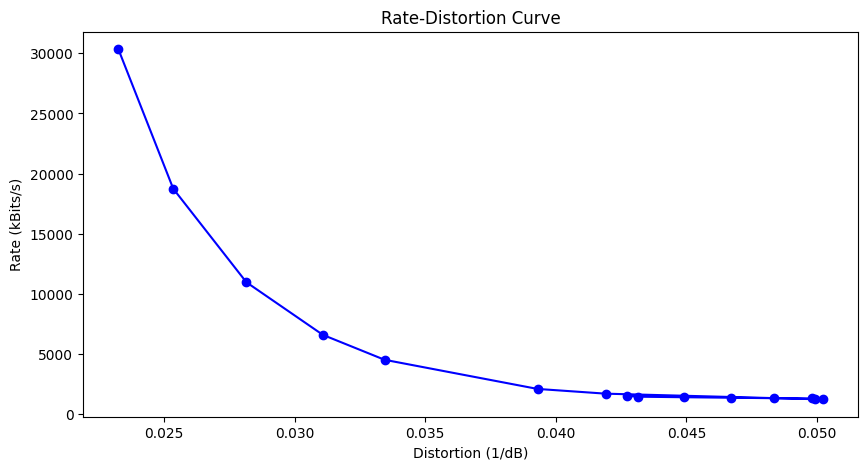

In [ ]:
distortion = []
for i in D:
    distortion.append(1/i)

plt.figure(figsize=(10, 5))
plt.plot(distortion,R, marker='o', linestyle='-', color='b')
plt.ylabel("Rate (kBits/s)")
plt.xlabel("Distortion (1/dB)")
plt.title("Rate-Distortion Curve")
# print the each point Qlevel
# for i in range(len(Qlevels_list)):
#     plt.text(distortion[i], R[i], f"{Qlevels_list[i]}")

In [ ]:
### Ploting the Qvalue-Distortion Curve

In [ ]:
bit_rate = 15000
frame_1_path = "frames/frame1.jpg"
frame_1 = cv2.imread(frame_1_path, cv2.IMREAD_GRAYSCALE)
Q_factor,R,D,Qlevels_list= rate_optimize(frame_1,bit_rate)
Q_factor = np.round(Q_factor, 1)  # Round to 1 decimal places for cleaner display
print(Q_factor)

macroblocksize = 8

# Create a directory to store the decoded frames
import os
if not os.path.exists(f"decoded_frames/decoded_frames_{Q_factor}"):
    os.makedirs(f"decoded_frames/decoded_frames_{Q_factor}")

for i in range(1,len(frames)+1):
    frame = frames[i-1]
    frame = cv2.imread(frame, cv2.IMREAD_GRAYSCALE)
    padded_frame = padding(frame, macroblocksize)
    macroblocks = DevideToMacroblocks(padded_frame, macroblocksize)
    
    #Assume IPPP GOP structure 
    # Encoding
    if i % 4 == 1:
        # ref_macroblocks = macroblocks
        dc_huffman_encoded, ac_huffman_encoded,dc_huffman_dict, ac_huffman_dict = encode_image(macroblocks, Q_factor)
        
        dc_huffman_dict = {int(k): v for k, v in dc_huffman_dict.items()}
        ac_huffman_dict = {int(k): v for k, v in ac_huffman_dict.items()}
        filename = f"decoded_frames/decoded_frames_{Q_factor}/frame_{i}_huffman_encoded_dc_datastream.txt"
        with open(filename, "w") as file:
            json.dump({"encoded_text": dc_huffman_encoded, "huffman_dict": dc_huffman_dict}, file)
        filename = f"decoded_frames/decoded_frames_{Q_factor}/frame_{i}_huffman_encoded_ac_datastream.txt"
        with open(filename, "w") as file:
            json.dump({"encoded_text": ac_huffman_encoded, "huffman_dict": ac_huffman_dict},file)

    else :
        motion_vectors, residuals = motion_estimate(macroblocks, ref_macroblocks, frame.shape, macroblocksize, P=7)
        dc_huffman_encoded, ac_huffman_encoded, dc_huffman_dict, ac_huffman_dict = encode_image(residuals, Q_factor)
        MV_huffman_encoded, MV_huffman_dict = MV_huffman_encode(motion_vectors)

        dc_huffman_dict = {int(k): v for k, v in dc_huffman_dict.items()}
        ac_huffman_dict = {int(k): v for k, v in ac_huffman_dict.items()}
        MV_huffman_dict = {int(k): v for k, v in MV_huffman_dict.items()}
        filename = f"decoded_frames/decoded_frames_{Q_factor}/frame_{i}_huffman_encoded_dc_datastream.txt"
        with open(filename, "w") as file:
            json.dump({"encoded_text": dc_huffman_encoded, "huffman_dict": dc_huffman_dict}, file)
        filename = f"decoded_frames/decoded_frames_{Q_factor}/frame_{i}_huffman_encoded_ac_datastream.txt"
        with open(filename, "w") as file:
            json.dump({"encoded_text": ac_huffman_encoded, "huffman_dict": ac_huffman_dict},file)
        filename = f"decoded_frames/decoded_frames_{Q_factor}/frame_{i}_huffman_encoded_MV_datastream.txt"
        with open(filename, "w") as file:
            json.dump({"encoded_text": MV_huffman_encoded, "huffman_dict": MV_huffman_dict},file)


    # Decoding
    decoded_macroblocks = decode_image(dc_huffman_encoded, ac_huffman_encoded, dc_huffman_dict, ac_huffman_dict, Q_factor)
    if i % 4 == 1:
        ref_macroblocks = decoded_macroblocks
        decoded_frame = decoded_macroblocks
        decoded_frame = reconstruct_image(decoded_frame, frame.shape, macroblocksize)
        decoded_frame = inverse_padding(decoded_frame,macroblocksize)
    else:
        decoded_residuals = decoded_macroblocks
        decoded_MV = MV_huffman_decode(MV_huffman_encoded, MV_huffman_dict)
        decoded_macroblocks = inverse_motion_estimate(ref_macroblocks, decoded_MV, decoded_residuals, frame.shape, macroblocksize)
        ref_macroblocks = decoded_residuals
        decoded_frame = reconstruct_image(decoded_macroblocks, frame.shape, macroblocksize)
        decoded_frame = inverse_padding(decoded_frame,macroblocksize)

    # plt.figure(figsize=(10, 10))
    # plt.subplot(1, 2, 1)
    # plt.imshow(frame, cmap='gray')
    # plt.title("Original Frame")
    
    # plt.subplot(1, 2, 2)
    # plt.imshow(decoded_frame, cmap='gray')
    # plt.title("Decoded Frame")
    # plt.show()

    cv2.imwrite(f"decoded_frames/decoded_frames_{Q_factor}/decoded_frame{i}.jpg", decoded_frame)

Qlevel = 1 ,  Bitrate = 30335.07
Qlevel = 2 ,  Bitrate = 18740.25
Qlevel = 4 ,  Bitrate = 10965.24
Qlevel = 3.7777777777777777 ,  Bitrate = 11504.43
Qlevel = 3.5555555555555554 ,  Bitrate = 12125.46
Qlevel = 3.3333333333333335 ,  Bitrate = 12762.84
Qlevel = 3.111111111111111 ,  Bitrate = 13465.08
Qlevel = 2.888888888888889 ,  Bitrate = 14245.44
Qlevel = 2.666666666666667 ,  Bitrate = 15154.23
Final Qlevel = 2.666666666666667
2.7


### Ploting decoded frames for bitrate 15000

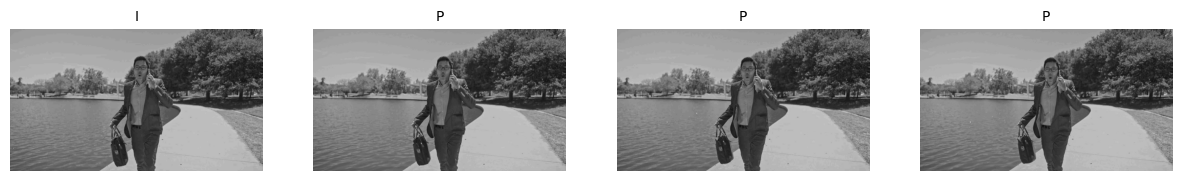

In [ ]:
fig, axs = plt.subplots(1, 4, figsize=(15, 15))
for i in range(1, 5):
    # Set titles for each column (I-frame for the first, P-frames for others)
    axs[i-1].set_title('I' if i == 1 else 'P', fontsize=10)

    # Load and display original frame
    decoded_frame_q = cv2.imread(f"decoded_frames/decoded_frames_{Q_factor}/decoded_frame{i}.jpg")
    axs[i-1].imshow(decoded_frame_q, cmap='gray')
    axs[i-1].axis('off')

# fig.text(0.5, 0.57, f"Decoded Frames(Q={Q_factor})", ha='center', va='center', fontsize=10, fontweight='bold')
plt.show()

## 3.3.2

In [383]:
def Qlty_optimize(input_image, psnr_value):
    psnr_values = []
    macroblocksize = 8
    padded_image = padding(input_image, macroblocksize)
    macroblocks_image = DevideToMacroblocks(padded_image, macroblocksize)
    
    testQ = [1, 1.5,2, 4, 9, 20, 25, 40]
    j = 1
    x = float('inf')
    
    while True:
        if psnr_value < x and j <= len(testQ):
            Qlevel = testQ[j - 1]
            j += 1
        elif j <= len(testQ):
            Qlevel = testQ[j - 2]
            break
        else:
            Qlevel = testQ[-1]
            break
       
        dc_huffman_encoded, ac_huffman_encoded, dc_huffman_dict, ac_huffman_dict = encode_image(macroblocks_image, Qlevel)
        Decoded_image = decode_image(dc_huffman_encoded, ac_huffman_encoded, dc_huffman_dict, ac_huffman_dict,Qlevel)
        Reconstruct_image= reconstruct_image(Decoded_image,input_image.shape, macroblocksize)
        IMG1 = inverse_padding(Reconstruct_image,macroblocksize)
        
        x = calculate_psnr(input_image,IMG1)
        psnr_values.append(x)
    
    print(f'Max possible PSNR value = {psnr_values[0]} Final Qlevel = {Qlevel}')
    return Qlevel, psnr_values[0]

In [ ]:
# frame_1_path = "frames/frame1.jpg"
# frame_1 = cv2.imread(frame_1_path, cv2.IMREAD_GRAYSCALE)
# Qfactor,psnr_vales= Qlty_optimize(frame_1,30)
# print(Qfactor)
# print(psnr_vales)

In [387]:
target_psnr_value = 40
macroblockSize = 8
# Qlevel = None
Psnr_values_of_frames = []
Q_values_of_frames = []
testQ = [1, 1.5,2, 4, 9, 20, 25, 40]
output = []

# Initial parameters
# frame_1_path = "frames/frame1.jpg"
frame_1 = cv2.imread(frames[0], cv2.IMREAD_GRAYSCALE)

# Find initial Q value for given PSNR
Q_factor, best_psnr_value = Qlty_optimize(frame_1, target_psnr_value)
# print(f"Qlevel = {Q_factor}")
# print(f"best_psnr_value = {best_psnr_value}")

# Main Loop
if not os.path.exists(f"decoded_frames_optimized/"):
    os.makedirs(f"decoded_frames_optimized/")

for i in range(1,len(frames)+1):
    frame = frames[i-1]
    frame = cv2.imread(frame, cv2.IMREAD_GRAYSCALE)
    padded_frame = padding(frame, macroblocksize)
    macroblocks = DevideToMacroblocks(padded_frame, macroblocksize)

    while True:

        if i % 4 == 1:
            # ref_macroblocks = macroblocks
            dc_huffman_encoded, ac_huffman_encoded,dc_huffman_dict, ac_huffman_dict = encode_image(macroblocks, Q_factor)

            dc_huffman_dict = {int(k): v for k, v in dc_huffman_dict.items()}
            ac_huffman_dict = {int(k): v for k, v in ac_huffman_dict.items()}
            filename = f"decoded_frames_optimized/frame_{i}_huffman_encoded_dc_datastream.txt"
            with open(filename, "w") as file:
                json.dump({"encoded_text": dc_huffman_encoded, "huffman_dict": dc_huffman_dict}, file)
            filename = f"decoded_frames_optimized/frame_{i}_huffman_encoded_ac_datastream.txt"
            with open(filename, "w") as file:
                json.dump({"encoded_text": ac_huffman_encoded, "huffman_dict": ac_huffman_dict},file)

        else :
            motion_vectors, residuals = motion_estimate(macroblocks, ref_macroblocks, frame.shape, macroblocksize, P=7)
            dc_huffman_encoded, ac_huffman_encoded, dc_huffman_dict, ac_huffman_dict = encode_image(residuals, Q_factor)
            MV_huffman_encoded, MV_huffman_dict = MV_huffman_encode(motion_vectors)

            dc_huffman_dict = {int(k): v for k, v in dc_huffman_dict.items()}
            ac_huffman_dict = {int(k): v for k, v in ac_huffman_dict.items()}
            MV_huffman_dict = {int(k): v for k, v in MV_huffman_dict.items()}
            filename = f"decoded_frames_optimized/frame_{i}_huffman_encoded_dc_datastream.txt"
            with open(filename, "w") as file:
                json.dump({"encoded_text": dc_huffman_encoded, "huffman_dict": dc_huffman_dict}, file)
            filename = f"decoded_frames_optimized/frame_{i}_huffman_encoded_ac_datastream.txt"
            with open(filename, "w") as file:
                json.dump({"encoded_text": ac_huffman_encoded, "huffman_dict": ac_huffman_dict},file)
            filename = f"decoded_frames_optimized/frame_{i}_huffman_encoded_MV_datastream.txt"
            with open(filename, "w") as file:
                json.dump({"encoded_text": MV_huffman_encoded, "huffman_dict": MV_huffman_dict},file)
                    

        # Decoding
        decoded_macroblocks = decode_image(dc_huffman_encoded, ac_huffman_encoded, dc_huffman_dict, ac_huffman_dict, Q_factor)
        if i % 4 == 1:
            ref_macroblocks = decoded_macroblocks
            decoded_frame = decoded_macroblocks
            decoded_frame = reconstruct_image(decoded_frame, frame.shape, macroblocksize)
            decoded_frame = inverse_padding(decoded_frame,macroblocksize)
        else:
            decoded_residuals = decoded_macroblocks
            decoded_MV = MV_huffman_decode(MV_huffman_encoded, MV_huffman_dict)
            decoded_macroblocks = inverse_motion_estimate(ref_macroblocks, decoded_MV, decoded_residuals, frame.shape, macroblocksize)
            ref_macroblocks = decoded_residuals
            decoded_frame = reconstruct_image(decoded_macroblocks, frame.shape, macroblocksize)
            decoded_frame = inverse_padding(decoded_frame,macroblocksize)


        # Feedback loop for quality
        temp = calculate_psnr(frame, decoded_frame)
        print(f"Frame {i} PSNR: {temp}, Q: {Q_factor}")
        if temp > target_psnr_value :
            Psnr_values_of_frames.append(np.round(temp,2))
            Q_values_of_frames.append(Q_factor)
            cv2.imwrite(f"decoded_frames_optimized/decoded_frame{i}.jpg", decoded_frame)
            break

        elif Q_factor != 1:
            index = testQ.index(Q_factor)
            Q_factor = testQ[index - 1]
            continue
        else:
            Psnr_values_of_frames.append(np.round(temp,2))
            Q_values_of_frames.append(Q_factor)
            cv2.imwrite(f"decoded_frames_optimized/decoded_frame{i}.jpg", decoded_frame)
            break


# Display PSNR values
print(Psnr_values_of_frames)
print(Q_values_of_frames)


Max possible PSNR value = 43.00086975097656 Final Qlevel = 2
Frame 1 PSNR: 39.43914031982422, Q: 2
Frame 1 PSNR: 40.94528579711914, Q: 1.5
Frame 2 PSNR: 41.05115509033203, Q: 1.5
Frame 3 PSNR: 39.64546585083008, Q: 1.5
Frame 3 PSNR: 41.902748107910156, Q: 1
Frame 4 PSNR: 40.09355545043945, Q: 1
Frame 5 PSNR: 42.838226318359375, Q: 1
Frame 6 PSNR: 42.7999153137207, Q: 1
Frame 7 PSNR: 41.399147033691406, Q: 1
Frame 8 PSNR: 41.84661865234375, Q: 1
Frame 9 PSNR: 42.83146667480469, Q: 1
Frame 10 PSNR: 42.57514953613281, Q: 1
[np.float32(40.95), np.float32(41.05), np.float32(41.9), np.float32(40.09), np.float32(42.84), np.float32(42.8), np.float32(41.4), np.float32(41.85), np.float32(42.83), np.float32(42.58)]
[1.5, 1.5, 1, 1, 1, 1, 1, 1, 1, 1]


### Ploting decoded frames for target PSNR value = 40

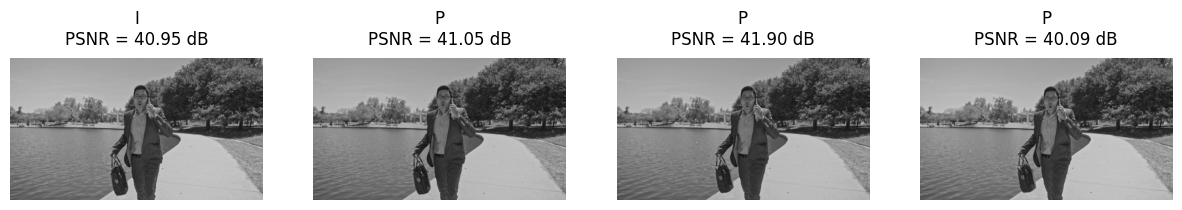

In [397]:
# Psnr_values_of_frames = np.array(Psnr_values_of_frames)
# Original frames
fig, axs = plt.subplots(1, 4, figsize=(15, 15))
for i in range(1, 5):
    # Combine frame type and PSNR into one title
    title_text = f"{'I' if i == 1 else 'P'}\nPSNR = {Psnr_values_of_frames[i-1]:.2f} dB"
    axs[i-1].set_title(title_text, fontsize=12, pad=10)

    # Load and display original frame
    decoded_frame_q = cv2.imread(f"decoded_frames_optimized/decoded_frame{i}.jpg", cv2.IMREAD_GRAYSCALE)
    axs[i-1].imshow(decoded_frame_q, cmap='gray')
    axs[i-1].axis('off')

plt.show()
